# Promotion comparisons and post-promotion patterns

Reference: **Two_Analytics_Projects_Complete_Guide.docx, Steps 1.4.1–1.4.4**. SQL: `sql/04_promo.sql`; runner: `scripts/run_promotions.py`. The notebook reads exports without locking DBeaver.

These are associations in panel purchases, not causal effects or total store sales.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / 'exports/promotions/promo_lift.csv').exists():
    ROOT = ROOT / 'outputs/grocery-marketing-effectiveness'
DATA = ROOT / 'exports/promotions'
coverage = pd.read_csv(DATA / 'promotion_coverage.csv')
lift = pd.read_csv(DATA / 'promo_lift.csv')
post = pd.read_csv(DATA / 'post_promo_lift.csv')
positive = pd.read_csv(DATA / 'promo_lift_positive_baseline.csv')
observed = pd.read_csv(DATA / 'promo_lift_observed_only.csv')
checks = pd.read_csv(DATA / 'promotion_checks.csv')
assert checks.passed.astype(str).str.lower().eq('true').all()
assert int(coverage.eligible_pairs.iloc[0]) == 22776
assert int(coverage.pair_weeks.iloc[0]) == 1184352
assert int(lift.pair_weeks.sum()) == 52 * int(coverage.baseline_pairs.iloc[0])
print(f'{len(checks)} full-data checks passed')
display(coverage.T)

18 full-data checks passed


,0
pair_weeks,1.184352e+06
observed_metadata_pair_weeks,2.305090e+05
missing_metadata_pair_weeks,9.538430e+05
conflicting_metadata_pair_weeks,5.870000e+02
promoted_pair_weeks,2.305090e+05
promoted_share,1.946288e-01
eligible_pairs,2.277600e+04
baseline_pairs,2.218300e+04
zero_unit_baseline_pairs,5.340000e+02
observed_only_baseline_pairs,0.000000e+00


## 1. Product/store/week panel

Pairs must have purchases in at least 8 weeks. Each receives source weeks 2–53. Missing purchase records mean zero panel purchases, not proven zero store sales. Baselines require at least 4 weeks without recorded display/mailer and not immediately after a promotion.

,product_id,store_id,week,units,on_display,in_mailer,display_location,mailer_location,promo_observed,has_conflicting_codes,promoted,week_after,two_back,previous_promo_observed
0,1000148,346,2,0.0,False,True,0,A,True,False,True,False,False,False
1,1000148,346,3,0.0,False,False,UNOBSERVED,UNOBSERVED,False,False,False,True,False,True
2,1000148,346,4,0.0,False,False,UNOBSERVED,UNOBSERVED,False,False,False,False,True,False
3,1000148,346,5,0.0,False,False,UNOBSERVED,UNOBSERVED,False,False,False,False,False,False
4,1000148,346,6,0.0,False,False,UNOBSERVED,UNOBSERVED,False,False,False,False,False,False
5,1000148,346,7,1.0,False,False,UNOBSERVED,UNOBSERVED,False,False,False,False,False,False
6,1000148,346,8,0.0,False,False,UNOBSERVED,UNOBSERVED,False,False,False,False,False,False
7,1000148,346,9,0.0,False,False,UNOBSERVED,UNOBSERVED,False,False,False,False,False,False
8,1000148,346,10,0.0,False,False,UNOBSERVED,UNOBSERVED,False,False,False,False,False,False
9,1000148,346,11,0.0,False,False,UNOBSERVED,UNOBSERVED,False,False,False,False,False,False


,condition,pair_weeks,observed_units,expected_baseline_units,lift_index
0,Display + mailer,39165,37674.0,12016.365921,3.135224
1,Mailer only,108992,94231.0,40734.015770,2.313325
2,Display only,55369,29467.0,18477.590651,1.594743
3,Week after a promotion,115419,48280.0,42659.251536,1.131759
4,No promotion,834571,333341.0,333341.000000,1.000000


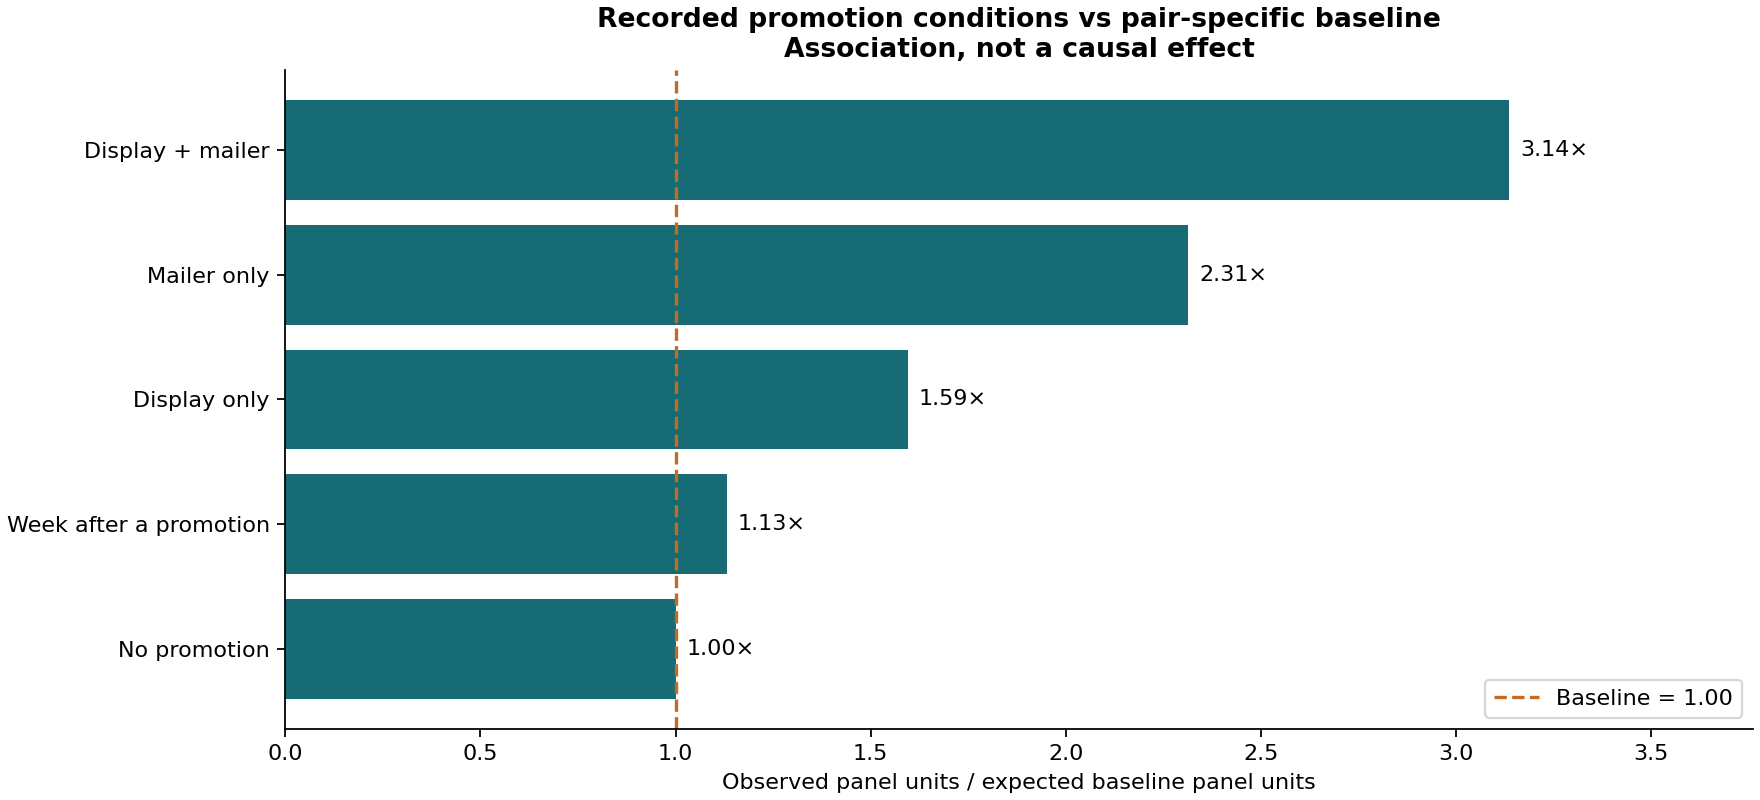

In [2]:
display(pd.read_csv(DATA / 'panel_sample.csv', dtype={'product_id': str, 'store_id': str}).head(15))
display(lift)
display(Image(filename=str(ROOT / 'charts/promotion_lift.png')))

## 2. Placement comparisons

Display-only and mailer-only groups are analysed separately. MULTIPLE preserves conflicting source codes. Counts below 100 are flagged and suppressed only in the chart; full exports retain them.

,placement_code,pair_weeks,observed_units,expected_baseline_units,lift_index,small_group,placement_label
0,1,3295,1852.0,912.136914,2.030397,False,Store front
1,A,3932,2363.0,1355.770350,1.742921,False,In-shelf
2,5,6855,3750.0,2164.246809,1.732704,False,Rear end cap
3,2,6101,2829.0,1767.117513,1.600912,False,Store rear
4,9,11501,6061.0,3873.611820,1.564690,False,Secondary display
5,6,3985,1783.0,1153.378387,1.545893,False,Side-aisle end cap
6,7,11315,6126.0,4081.559252,1.500897,False,In-aisle
7,4,1677,900.0,604.986888,1.487636,False,Mid-aisle end cap
8,3,6708,3803.0,2564.782718,1.482777,False,Front end cap


,placement_code,pair_weeks,observed_units,expected_baseline_units,lift_index,small_group,placement_label
0,D,36466,48981.0,15749.860190,3.109932,False,Front page feature
1,Z,50,55.0,20.775672,2.647327,True,Free front/back/wrap
2,H,6974,5929.0,2553.007824,2.322359,False,Wrap front feature
3,L,1033,697.0,313.643357,2.222269,False,Wrap back feature
4,F,15343,12590.0,6051.213010,2.080575,False,Back page feature
5,J,1167,691.0,410.622007,1.682813,False,Wrap interior coupon
6,A,45252,23857.0,14245.818374,1.674667,False,Interior page feature
7,C,1270,836.0,600.058308,1.393198,False,Interior line item
8,X,1436,595.0,788.930070,0.754186,False,Free on interior page
9,P,1,0.0,0.086957,0.000000,True,Interior coupon


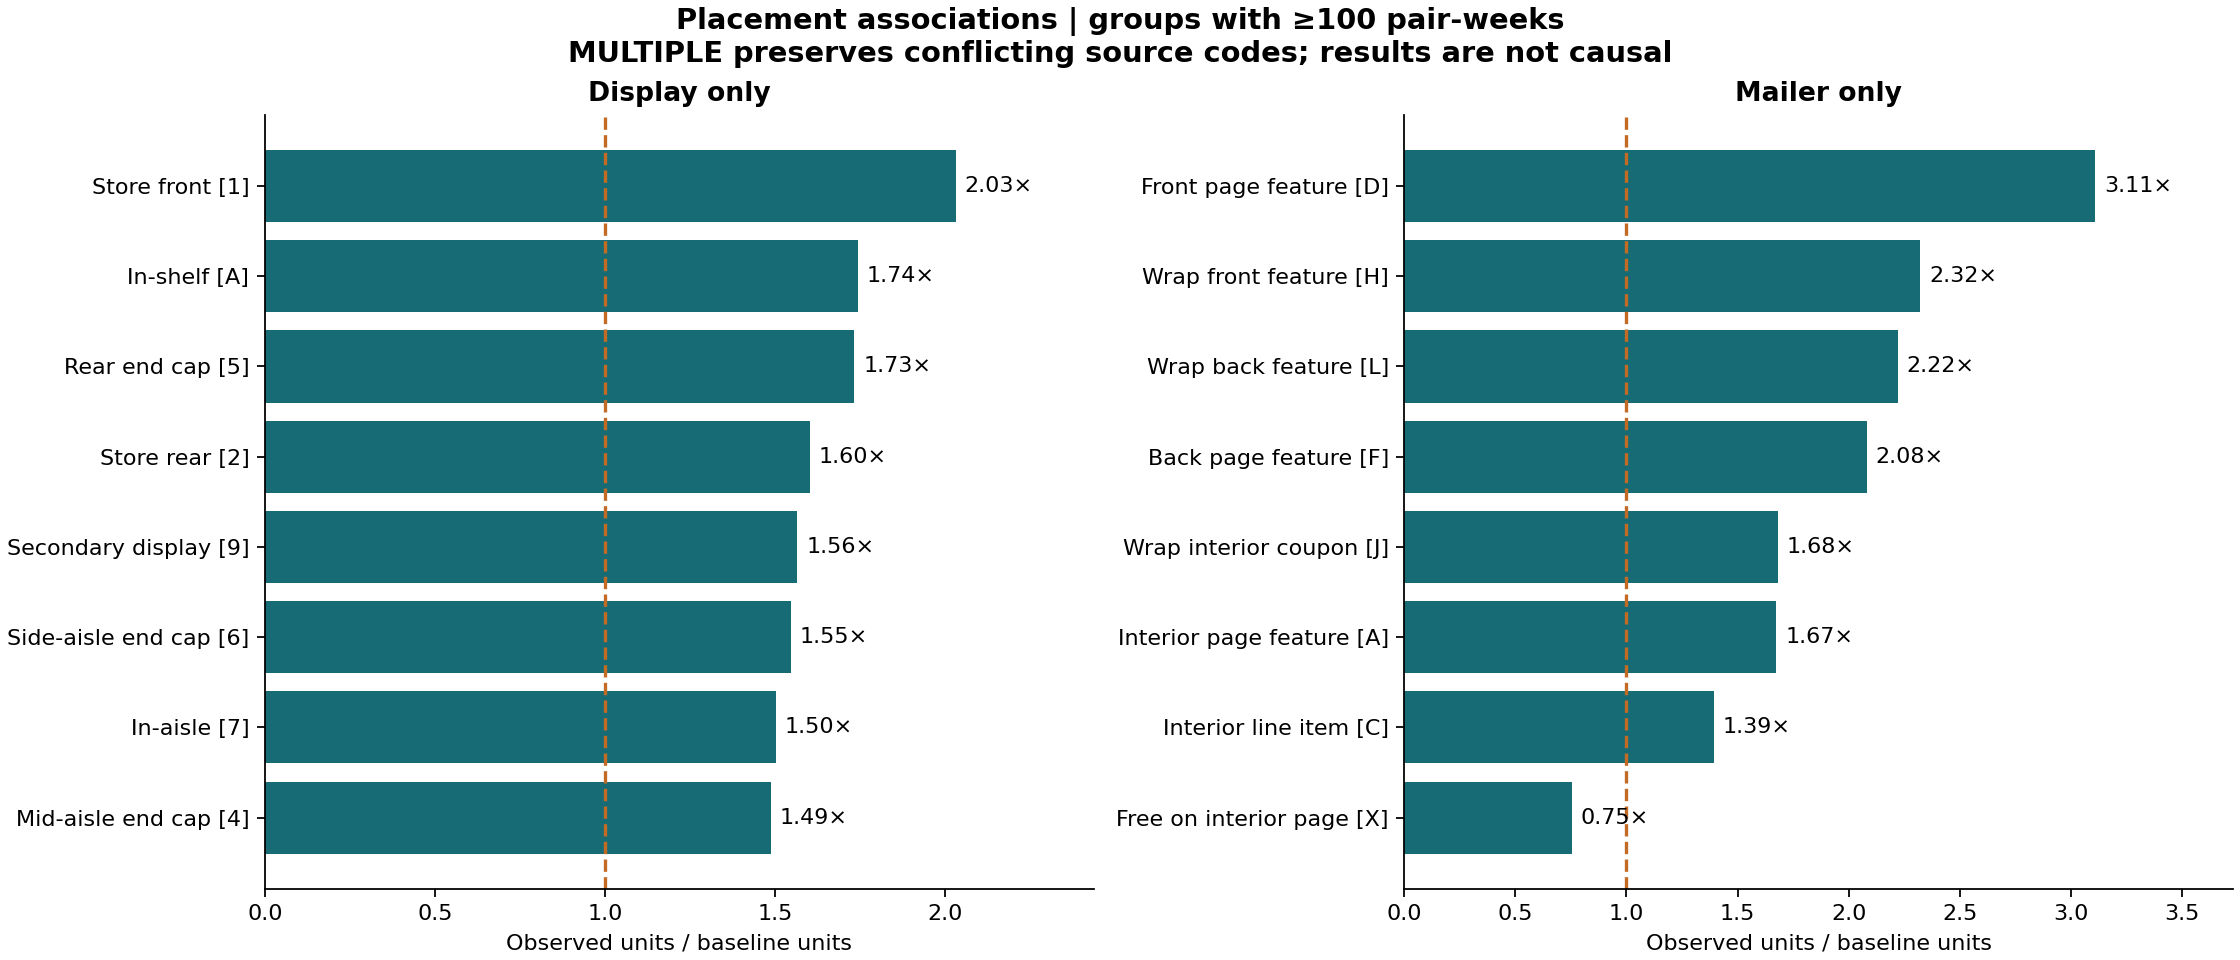

In [3]:
display(pd.read_csv(DATA / 'display_lift.csv', dtype={'placement_code': str}))
display(pd.read_csv(DATA / 'mailer_lift.csv', dtype={'placement_code': str}))
display(Image(filename=str(ROOT / 'charts/promotion_placements.png')))

## 3. Weeks after promotions

A single-week sequence means the previous week was promoted but the week before it was not recorded as promoted. Consecutive-week sequences have both previous weeks flagged. Boundary history is incomplete and counted explicitly. These comparisons do not isolate stockpiling or prove that there is no pull-forward effect.

,condition,pair_weeks,observed_units,expected_baseline_units,lift_index,boundary_history_incomplete_rows
0,Normal,834571,333341.0,333341.000000,1.000000,34505
1,Promoted,203526,161372.0,71227.972342,2.265571,7815
2,Week after a multi-week promotion,34428,14008.0,11737.323320,1.193458,0
3,Week after a single-week promotion,80991,34272.0,30921.928215,1.108340,2046


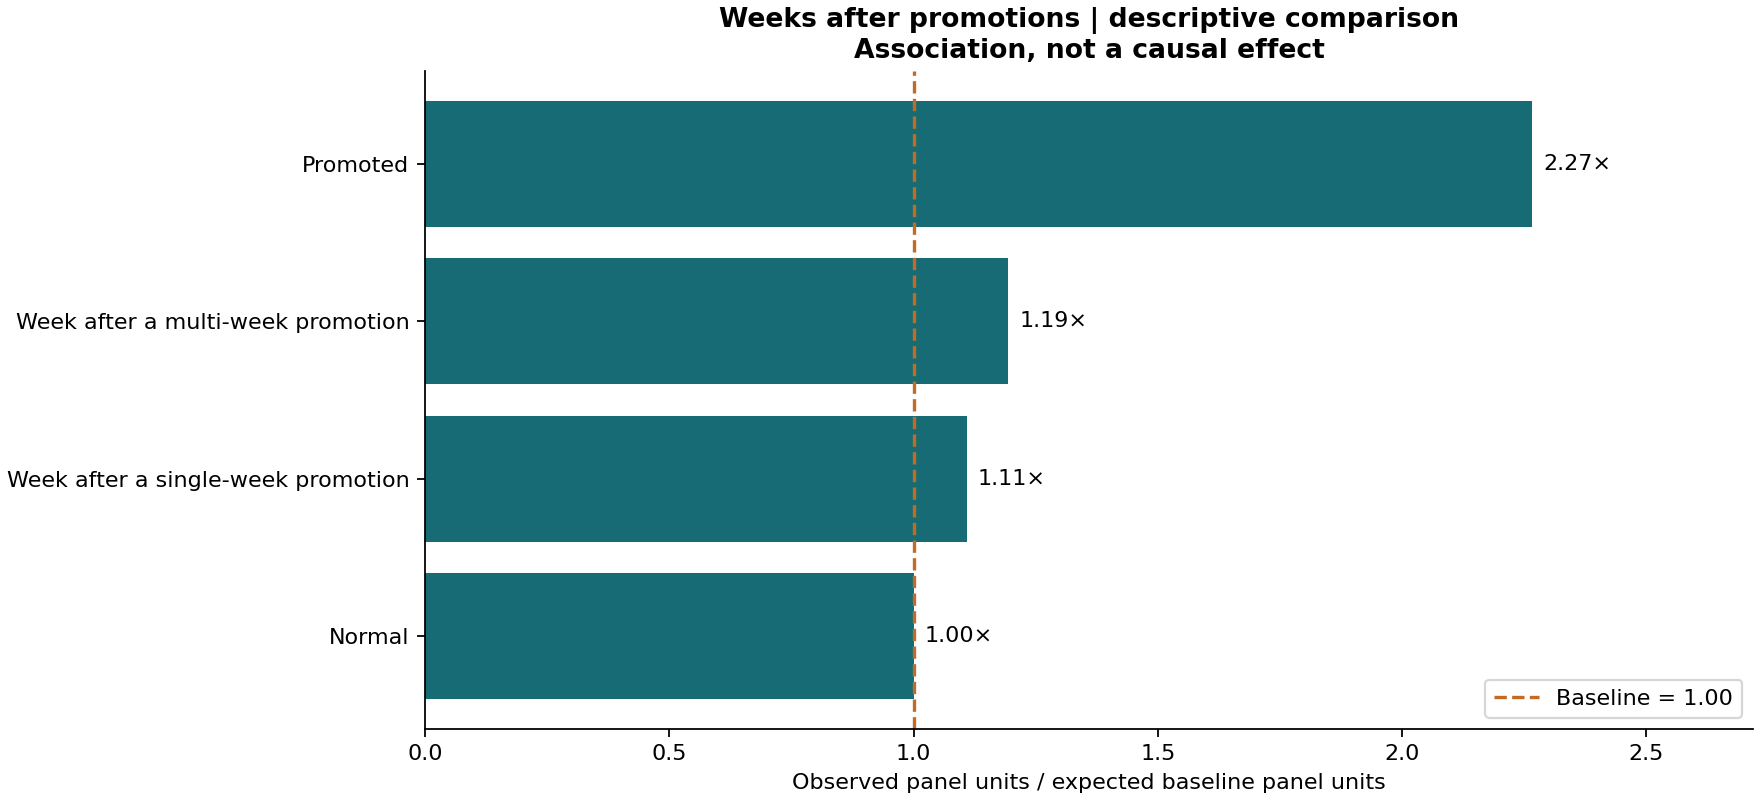

In [4]:
display(post)
display(Image(filename=str(ROOT / 'charts/post_promotion.png')))

## 4. Baseline and coverage sensitivity

The guide treats absent promotion rows as no recorded display/mailer. Every explicitly observed eligible record is promotional; therefore the observed-metadata-only baseline is unsupported, not a zero effect. Positive-baseline sensitivity is estimable and reported separately. Do not average indices across incompatible populations.

In [5]:
assert observed.empty
assert int(coverage.observed_only_baseline_pairs.iloc[0]) == 0
print('Observed-metadata-only comparison: NOT ESTIMABLE — no explicitly observed nonpromotion baselines.')
comparison = lift[['condition','lift_index']].merge(positive[['condition','lift_index']], on='condition', suffixes=('_primary','_positive_baseline'))
display(comparison)
display(checks)

Observed-metadata-only comparison: NOT ESTIMABLE — no explicitly observed nonpromotion baselines.


,condition,lift_index_primary,lift_index_positive_baseline
0,Display + mailer,3.135224,2.906869
1,Mailer only,2.313325,2.238473
2,Display only,1.594743,1.421181
3,Week after a promotion,1.131759,1.104309
4,No promotion,1.000000,1.000000


,check_name,passed
0,panel_grain_unique,True
1,52_rows_per_pair,True
2,panel_size_reconciles,True
3,eligible_pair_history,True
4,zero_fill_preserves_units,True
5,promotion_aggregation_unique,True
6,primary_baselines_have_four_weeks,True
7,observed_baselines_have_four_weeks,True
8,condition_counts_reconcile,True
9,post_condition_counts_reconcile,True


## 5. Findings and next step

In [6]:
display(Markdown((ROOT / 'docs/promotions/findings.md').read_text(encoding='utf-8')))

# Promotion associations

Completed **Steps 1.4.1–1.4.4**. Units are purchases by the panel households, not total store sales. These indices compare observed units with a pair-specific baseline; they are not randomized treatment effects.

## Three findings

1. Display plus mailer pair-weeks have **3.14×** baseline panel units, versus **2.31×** for mailer only and **1.59×** for display only. This ranks observed promotion packages, not the isolated causal effect of a display or mailer. An index of 3.14 means 214% above baseline, not a 314% increase.
2. The week after a single-week promotion has **1.11×** baseline units; after multiple consecutive promoted weeks, **1.19×**. The guide-style comparison does not show a dip below baseline. It cannot determine whether discounts continued, demand was seasonal, or purchases were pulled forward.
3. Metadata is absent for **953,843 of 1,184,352 pair-weeks**. All explicitly listed eligible records indicate a display or mailer, so an observed-metadata-only baseline is **not estimable**: it has no explicitly observed nonpromotion controls. The primary result follows the guide's convention that an absent row means no recorded display/mailer; that convention cannot be independently validated from explicit nonpromotion records in this source.

## Primary results

| Condition | Pair-weeks with usable baseline | Unit index |
|---|---:|---:|
| Display + mailer | 39,165 | 3.14× |
| Mailer only | 108,992 | 2.31× |
| Display only | 55,369 | 1.59× |
| Week after a promotion | 115,419 | 1.13× |
| No promotion | 834,571 | 1.00× |

## Universe and coverage

- **22,776 product/store pairs** purchased in at least eight source weeks; 52 weeks per pair gives **1,184,352 panel rows**.
- **22,183 pairs** have at least four baseline weeks (not promoted and not directly after a promotion).
- **19.5%** of the full eligible panel has recorded promotion flags.
- **587 eligible pair-weeks** contain conflicting placement codes. Flags use any nonzero code; labels use MULTIPLE instead of selecting an arbitrary maximum. Placement-specific values may therefore differ from the guide's maximum-code method.
- **534 pairs** have zero average baseline units. The primary result uses a ratio-of-totals definition; the positive-baseline-only export shows a sensitivity excluding these pairs.
- Missing purchase rows are zero-filled within this panel, meaning no observed panel purchase. This does not prove no store sales or product availability.

## Observed-metadata sensitivity

| Condition | Primary definition | Observed-current-and-prior metadata only |
|---|---:|---:|
| Display + mailer | 3.14× | Not estimable |
| Mailer only | 2.31× | Not estimable |
| Display only | 1.59× | Not estimable |
| Week after a promotion | 1.13× | Not estimable |
| No promotion | 1.00× | Not estimable |

The stricter sample has 0 usable baseline pairs. Its CSV intentionally contains headers and no estimates. This is a support limitation, not a zero effect or a failed query. It excludes boundary week 2 and missing-metadata transitions. Primary lag indicators default to no previous promotion at the left boundary as in the guide; boundary-history counts are exported for the post-promotion comparison.

The positive-baseline sensitivity remains estimable: excluding 534 zero-baseline pairs changes the Display + mailer index to 2.91×, Mailer only to 2.24×, and Display only to 1.42×. These are alternate descriptive estimates, not corrected causal effects. The complete base amounts and counts are exported.

Placement-code definitions follow the [official completejourney documentation](https://github.com/bradleyboehmke/completejourney/blob/master/man/promotions_sample.Rd). The event-style support limitation above is an observation from this full dataset, not a claim that the documentation independently proves missing-record coverage.

## Interpretation and verification

Price discounts can accompany display and mailer exposure. Seasonality, selection of products into promotion, availability, and other confounders remain uncontrolled. Small placement groups (<100 pair-weeks) are flagged and omitted from the placement chart; the full CSV retains them. This threshold is a descriptive display rule, not a statistical significance test. No confidence intervals or profit/ROI claims are made.

**18 full-data checks passed**, covering panel grain, zero filling, baseline support, condition totals, coverage, and ratios. Source fingerprints were verified before analysis. The raw data, user SQL scripts, and open databases were not modified.

Files: `exports/promotions/`, `sql/04_promo.sql`, `04_promotions.ipynb`, three PNG charts, and `grocery_promotions.duckdb` (summary/check tables only).


No promotion causal effect, profit estimate, or ROI has been established in this module; Module 5 tests campaign incrementality.